### Machine Learning Terminology
- Each row is an observation (also known as: sample, example, instance, record)
- Each column is a feature (also known as: predictor, attribute, independent variable, input, regressor, covariate)
- Each value we are predicting is the response (also known as: target, outcome, label, dependent variable)

### Types of Supervised Learning
- **Classification** is supervised learning which predicts a category, like “degraded” vs “healthy”. Logistic regression is the classic example. Despite its name, it outputs a class (or a probability of a class), not a number.
- **Regression** is supervised learning which predicts a number on a continuous scale, like a cell’s capacity, voltage, or degradation amount. Ridge, Lasso, and XGBRegressor are all regression models.

### Requirements for working with data in scikit-learn
  **Features** and **Response** are:
- Seperable objects
- should be numeric
- should be NumPy arrays
- Features should be a square grid while a feature should be corresponding column only

In [4]:
from sklearn.datasets import load_iris

#This is a Bunch 'Object' (It is an in-memory Python object) -> Acts like a Dictionary and stores 5 things
iris = load_iris()

# print(iris.data)
# print(iris.target)
# print(iris.feature_names)
# print(iris.target_names)
# print(iris.DESCR)

In [5]:
# store feature matrix in 'X'
x = iris.data

# store response matrix in 'X'
y = iris.target

In [6]:
# Checking the shape of 'x' and 'y'
print (x.shape)   # 150 rows, 4 coloumns  ->   150 readings across 4 observables
print (y.shape)   # 150 rows              ->   150 outputs corresponding to the observable

(150, 4)
(150,)


### scikit-learn 4-step modeling pattern
**Step 1:** Import the class you plan to us

In [7]:
# Since we are using K Neighbors Classifier method
from sklearn.neighbors import KNeighborsClassifier

**Step 2:** "Instantiate" the "estimator"
- "Estimator" is scikit-learn's term for model
- "Instantiate" means "make an instance of"

In [8]:
# We create an object knn which knows how to use K Nearest Neighbours 
# There are other Parameters in this class which we are not defining here which have stored their default values
# Here(K=1) so (n_neighbors = 1)
knn = KNeighborsClassifier(n_neighbors = 1)
print(knn)

KNeighborsClassifier(n_neighbors=1)


### Step 3: Fit the model with data (aka "model training")
- Model is learning the relationship between X and y
- Occurs in-place so we do not need to assign objects to store data

In [9]:
knn.fit(x,y)   # feature matrix'x', response vector 'y'
# This method does all the math behind the KNN method

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### Step 4: Predict the response for a new observation
- New observations are called "out-of-sample" data
- Uses the information it learned during the model training process
- Returns a NumPy array
- can predict for multiple observations at once

In [10]:
print(knn.predict([[3, 5, 4, 2]]))
print(knn.predict([[3, 5, 4, 2], [5, 4, 3, 2]]))
# needs a numpuy array or list of lists (which is converted to a numpy array inside) 

[2]
[2 1]


### 
Why Logistic Regression outputted `[0, 0]` for this specific array

Look at the measurements you passed for the first flower: `[3, 5, 4, 2]`
**Sepal Length:** 3 cm (unusually tiny for an Iris flower!)
**Sepal Width:** 5 cm *(very wide)*
**Petal Length:** 4 cm
**Petal Width:** 2 cm

**Logistic Regression** relies on linear decision boundaries across all 4 features combined. Because the sepal length is so small (`3`), the mathematical model calculated that this point falls into the `0` (Setosa) decision region rather than `2` (Virginica).

**K-Nearest Neighbors (KNN)**, on the other hand, looks only at the closest distance in space. Depending on whether you use KNN ($K=1$)[cite: 2] or Logistic Regression, decision boundaries differ significantly for unusual outlier measurements like `[3, 5, 4, 2]`.

### HOW DO I  ESTIMATE THE PERFORMANCE OF MY MODEL

- METHOD 1: TRAIN AND TEST ON THE ENTIRE DATASET (train the model on some dataset and then evaluate it against the same dataset)
- (NOT VERY USEFUL METHOD)

In [94]:
# LOGISTIC REGRESSION - CERTAIN METHOD 
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter = 1000)
logreg.fit (x,y)
y_pred = logreg.predict(x)
print (y_pred)

from sklearn import metrics
print(metrics.accuracy_score(y, y_pred))
# accuracy is still not 1 because data for 2 features is extremely similar in 4 cases -> so accuracy = (150-4)/150
# also called TRAINING ACCURACY

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1
 1 1 1 2 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
0.9733333333333334


In [32]:
# KNN (for k=1)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 1)
knn.fit(x,y)
y_pred = knn.predict(x)
print(y_pred)

from sklearn import metrics
print(metrics.accuracy_score(y, y_pred))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
1.0


In [33]:
# KNN (for k=5)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(x,y)
y_pred = knn.predict(x)
print(y_pred)

from sklearn import metrics
print(metrics.accuracy_score(y, y_pred))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1
 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 1 2 2 2 2
 2 2 2 2 2 2 2 2 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]
0.9666666666666667


In [34]:
# so best model to use according to this testing method is KNN for k=1

- METHOD 2: TRAIN/TEST SPLIT (SPLIT THE DATASET AND TRAIN AND TEST ON DIFFERENT PARTS)

In [49]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.4, random_state = 4)
# "test_size = 0.4" means that 40 percent of my data should be assigned to testing
# THIS IS A NEW SYNTAX -> "train_test_split(x, y, test_size = 0.4)" RETURNS A TOUPLE

In [50]:
%%capture
print(x_train)
print()
print(x_test)
print()
print(y_train)
print()
print(y_test)

In [51]:
# FOR LOGISTIC REGRESSION
logreg = LogisticRegression(max_iter = 1000)
logreg.fit (x_train,y_train)
y_pred = logreg.predict(x_test)
print(metrics.accuracy_score(y_test, y_pred))

0.9666666666666667


In [44]:
# FOR KNN (k=1)
knn = KNeighborsClassifier(n_neighbors = 1)
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
print(metrics.accuracy_score(y_test, y_pred))

0.95


In [55]:
# FOR KNN (k=5)
knn = KNeighborsClassifier(n_neighbors = 5)
knn.fit(x_train,y_train)
y_pred = knn.predict(x_test)
print(metrics.accuracy_score(y_test, y_pred))

0.9666666666666667


In [74]:
# TRYING TO FIND THE BEST VALUE FOR k IN KNN
k_range = range(1,26)
scores = [] # EMPTY LIST
k_best_accuracy = 0
k_best = 1

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors = k)
    knn.fit(x_train,y_train)
    y_pred = knn.predict(x_test)
    k_new_accuracy = metrics.accuracy_score(y_test, y_pred)
    scores.append(k_new_accuracy)

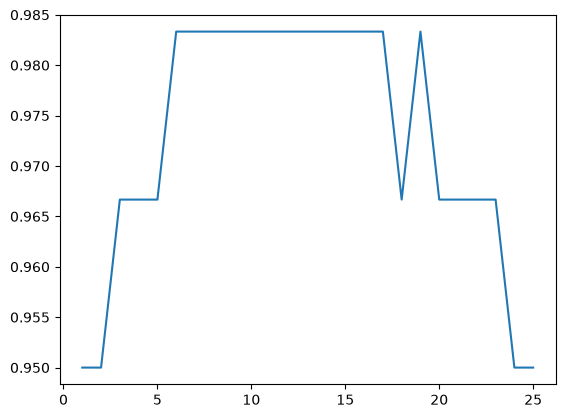

In [75]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.plot(k_range, scores)

In [76]:
# so best value of k is from 6-16 so i will take k=11 as the best k

In [82]:
# CROSS VALIDATION
from sklearn.model_selection import cross_val_score

knn = KNeighborsClassifier(n_neighbors = 5)
scores = cross_val_score(knn, x, y, cv=10, scoring='accuracy') # RETURNS A LIST
# 'knn' is model object, 'x,y' entire feature and response vetors, 'cv=10' means we want 10 cross validation, 
# "scoring='accuracy'" means we want to use classification accuracy as the evaluation metric
print(scores)
print(scores.mean())
# consider 10 fold cross validation involving 2 types of results a,b (20 and 80% respectively )
# so my dataset is being divided into 10 parts where each part hasa 20% a and 80% b 
# this is done by cross_val_score under the hood

[1.         0.93333333 1.         1.         0.86666667 0.93333333
 0.93333333 1.         1.         1.        ]
0.9666666666666668



### SUMMARY: Hyperparameter Tuning & K fold Cross-Validation Workflow (KNN Example)
- we keep K=10 always (experimentally best value)
- then for given k value , we evaluate across K(=10) folds and take the average of the accuracy values
- we repeat this process for multiple k and select the k with the highest average accuracy
- we use this k to make predictions on newer data

Text(0, 0.5, 'Cross-Validated Accuracy')

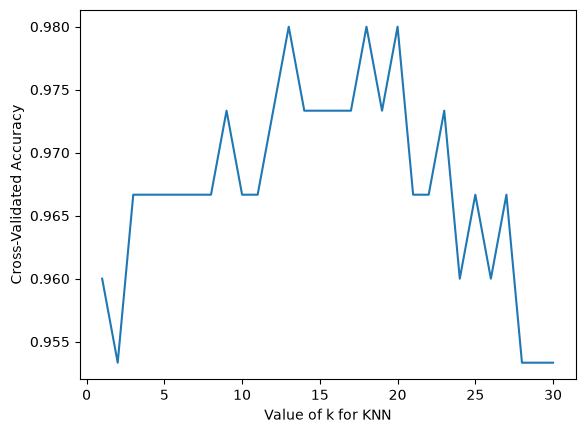

In [88]:
# TO SUM IT ALL UP 
k_range = range(1,31)
k_scores = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors = k)
    scores = cross_val_score(knn, x, y, cv=10, scoring='accuracy')
    k_scores.append(scores.mean())
plt.plot(k_range, k_scores)
plt.xlabel('Value of k for KNN')
plt.ylabel('Cross-Validated Accuracy')
# AS WE CAN SEE, THERE IS A MAX FOR k=20

In [90]:
knn = KNeighborsClassifier(n_neighbors = 20)
print(cross_val_score(knn, x, y, cv=10, scoring='accuracy').mean())

0.9800000000000001


In [98]:
# LOGISTIC REGRESSION USING K FOLD CROSS VERIFICATION (K=10)
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter = 1000)
print(cross_val_score(logreg, x, y, cv=10, scoring='accuracy').mean())

0.9733333333333334
